| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../11_MACHINE_LEARNING/11_3_Unsupervised_Learning.ipynb) | [⏩](../12_DEEP_LEARNING/12_1_Neural_Networks.ipynb) |

# 11.4 Teoría del aprendizaje estadístico: riesgo, capacidad y generalización

**Objetivo del cuaderno.** conectar riesgo empírico con riesgo esperado, estudiar sesgo-varianza y reconocer las hipótesis de cotas de generalización

**Antes de empezar:** probabilidad, esperanza, concentración y aprendizaje supervisado. Ejecuta las celdas de arriba hacia abajo. Los datos se generan localmente y la semilla hace repetible el experimento; las conclusiones numéricas corresponden a este conjunto de datos.

**Ruta de estudio:** primero formula el problema y entiende las ecuaciones; después compara las figuras con las predicciones teóricas; finalmente modifica un parámetro y resuelve los ejercicios. En cada gráfico distinguimos lo que demuestra el experimento de lo que requiere una hipótesis matemática.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize
np.set_printoptions(precision=5, suppress=True)
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.grid': True, 'font.size': 11})
rng = np.random.default_rng(42)
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression
from sklearn.metrics import mean_squared_error, r2_score, confusion_matrix, classification_report

## 1. La pregunta central: ¿por qué generaliza un ajuste?

Aprender de una muestra requiere una relación entre los casos observados y los futuros. La teoría clásica supone muestras independientes e idénticamente distribuidas de una distribución $P$. Una trayectoria física autocorrelacionada no satisface esa hipótesis punto a punto; aplicar una cota i.i.d. sin adaptación puede sobreestimar información.

Una clase $\mathcal H$ contiene predictores posibles. El riesgo esperado $R(h)=\mathbb E\ell(h(X),Y)$ depende de $P$, mientras el riesgo empírico $\hat R_n(h)=n^{-1}\sum_i\ell(h(x_i),y_i)$ depende de la muestra. El objetivo es controlar su diferencia y la calidad del predictor elegido con datos.

## 2. Tres fuentes distintas de error

Sea $h^*$ un predictor ideal y $h_{\mathcal H}^*$ el mejor disponible en la clase. El riesgo aprendido puede descomponerse conceptualmente en:

- **Aproximación:** la clase no representa bien la relación verdadera.
- **Estimación:** elegimos con datos finitos en lugar de conocer $P$.
- **Optimización:** no encontramos el mejor objetivo empírico disponible.

Aumentar capacidad puede reducir aproximación y aumentar estimación. Entrenar más solo aborda optimización; no elimina ruido ni falta de información. SciML intenta reducir aproximación y estimación mediante estructura física, pero una física incorrecta también introduce sesgo.

## 3. Ley de grandes números no basta tras seleccionar

Para un predictor fijo, promediar muchos errores aproxima su esperanza bajo hipótesis apropiadas. Sin embargo, elegimos el predictor mirando los datos. Comparar miles de opciones y reportar el menor error observado introduce optimismo de selección.

La convergencia uniforme busca controlar simultáneamente $\sup_{h\in\mathcal H}|R(h)-\hat R_n(h)|$. La complejidad de la clase aparece porque queremos una afirmación válida incluso después de escoger un elemento con la misma muestra.

## 4. Hoeffding para pérdidas acotadas

Si las pérdidas de un predictor fijo son independientes y pertenecen a $[0,1]$, Hoeffding da

$$\Pr(|\hat R_n-R|>\epsilon)\le2e^{-2n\epsilon^2}.$$

Para una clase finita de $M$ predictores fijada independientemente de la muestra, una unión de eventos produce, con probabilidad al menos $1-\delta$,

$$\sup_{h\in\mathcal H}|\hat R_n(h)-R(h)|\le\sqrt{\frac{\log(2M/\delta)}{2n}}.$$

La cota puede ser conservadora y hasta mayor que uno. No la aplicamos directamente a MSE gaussiano, cuya pérdida no es acotada en $[0,1]$. El código visualiza la expresión y su dependencia de capacidad y muestra.

Cota n=200, M=1000: 0.16276236307187292


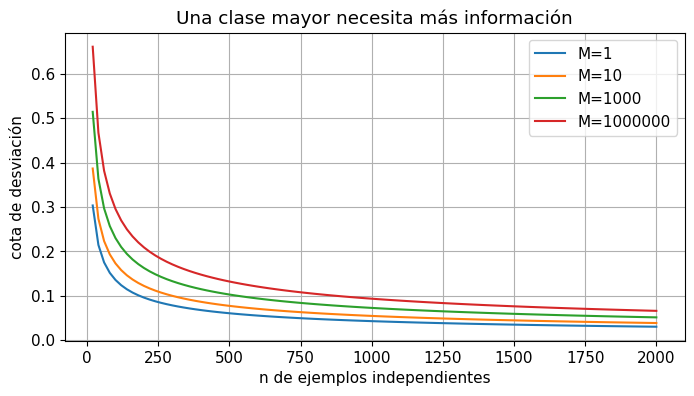

In [2]:
sizes=np.arange(20,2001,20);delta=0.05
for M in [1,10,1000,1000000]:
    bound=np.sqrt(np.log(2*M/delta)/(2*sizes))
    plt.plot(sizes,bound,label=f'M={M}')
plt.xlabel('n de ejemplos independientes');plt.ylabel('cota de desviación');plt.title('Una clase mayor necesita más información')
plt.legend();plt.show()
print('Cota n=200, M=1000:',np.sqrt(np.log(2*1000/delta)/(2*200)))

**Interpretación.** La cota baja como $n^{-1/2}$ y depende logarítmicamente de $M$. No predice una curva exacta de test: es un límite probabilístico bajo pérdidas acotadas y muestra i.i.d. En SciML no debemos reemplazar $n$ por millones de puntos vecinos y asumir que todos son independientes.

## 5. VC y Rademacher: clases infinitas

La dimensión VC de una clase binaria es el mayor número de puntos que puede separar con todas las etiquetas posibles. En posiciones apropiadas, los hiperplanos afines en $\mathbb R^d$ tienen dimensión VC $d+1$. Es una noción de capacidad combinatoria, no una medida de precisión de un modelo ya ajustado.

La complejidad de Rademacher evalúa cuánto puede una clase correlacionarse con etiquetas aleatorias. Puede adaptarse a normas y datos. Estas herramientas permiten estudiar clases infinitas donde contar $M$ no funciona. El número bruto de parámetros de una red no resume por sí solo todas sus propiedades de generalización.

## 6. Sesgo-varianza bajo pérdida cuadrática

Con $Y=f^*(x)+\epsilon$ y ruido de media cero independiente del entrenamiento, para un $x$ fijo:

$$\mathbb E_{\mathcal D,\epsilon}(\hat f_{\mathcal D}(x)-Y)^2=\underbrace{(\mathbb E_{\mathcal D}\hat f_{\mathcal D}(x)-f^*(x))^2}_{\text{sesgo}^2}+\underbrace{\operatorname{Var}_{\mathcal D}\hat f_{\mathcal D}(x)}_{\text{varianza}}+\underbrace{\operatorname{Var}(\epsilon)}_{\text{ruido}}.$$

La esperanza incluye distintos conjuntos de entrenamiento. No se estima la varianza del predictor usando solo un ajuste. Por ello repetimos conjuntos sintéticos manteniendo la misma función verdadera y malla de evaluación.

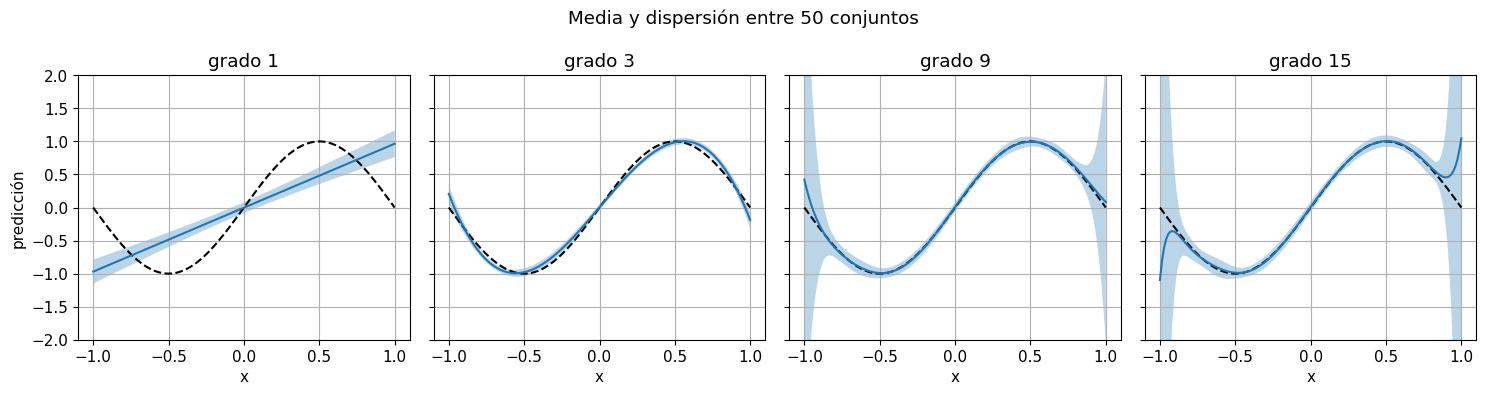

In [3]:
grid=np.linspace(-1,1,150)[:,None]
def ftrue(z):return np.sin(np.pi*z)
sigma=0.15;degrees=[1,3,9,15];ensemble={}
for degree in degrees:
    preds=[]
    for repeat in range(50):
        local=np.random.default_rng(100+repeat)
        X=local.uniform(-1,1,(35,1));y=ftrue(X[:,0])+local.normal(0,sigma,35)
        model=make_pipeline(PolynomialFeatures(degree,include_bias=False),StandardScaler(),Ridge(alpha=1e-5))
        model.fit(X,y);preds.append(model.predict(grid))
    ensemble[degree]=np.array(preds)
fig,axes=plt.subplots(1,4,figsize=(15,4),sharey=True)
for ax,degree in zip(axes,degrees):
    predictions=ensemble[degree];mean=predictions.mean(axis=0);sd=predictions.std(axis=0)
    ax.plot(grid[:,0],ftrue(grid[:,0]),'k--');ax.plot(grid[:,0],mean)
    ax.fill_between(grid[:,0],mean-sd,mean+sd,alpha=0.3)
    ax.set(title=f'grado {degree}',xlabel='x',ylim=(-2,2))
axes[0].set_ylabel('predicción');plt.suptitle('Media y dispersión entre 50 conjuntos');plt.tight_layout();plt.show()

**Interpretación.** Un grado bajo puede omitir la curvatura real y tener sesgo. Un grado grande puede variar mucho entre conjuntos, especialmente cerca de bordes. La banda representa dispersión entre estimadores sintéticos, no un intervalo de predicción de una sola observación ni una banda de confianza exacta.

## 7. Cuantificar la descomposición

Calculamos sesgo cuadrático y varianza sobre la malla; añadimos la varianza conocida de ruido. Esta evaluación usa la verdad sintética y repeticiones independientes. En datos reales la separación precisa suele ser difícil.

grado= 1 sesgo²= 0.20114576863632602 varianza= 0.016887038310263492 total= 0.24053280694658952
grado= 3 sesgo²= 0.004670727379215195 varianza= 0.0035831035852672585 total= 0.030753830964482455
grado= 9 sesgo²= 0.0032820802513782985 varianza= 0.3968470158500924 total= 0.4226290961014707
grado= 15 sesgo²= 0.03381444656044992 varianza= 3.119272089404435 total= 3.175586535964885


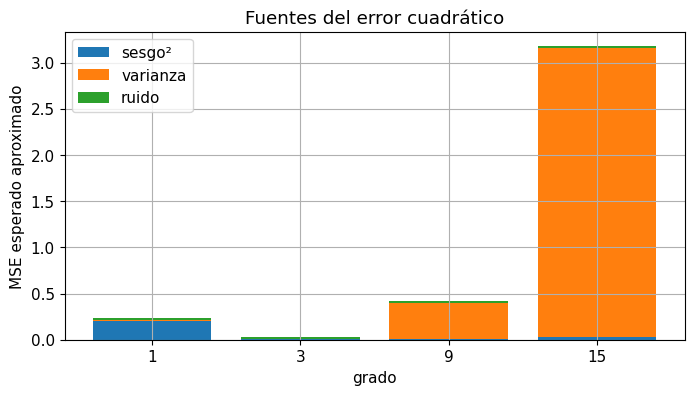

In [4]:
bias2=[];variance=[]
for degree in degrees:
    P=ensemble[degree]
    bias2.append(np.mean((P.mean(axis=0)-ftrue(grid[:,0]))**2))
    variance.append(np.mean(P.var(axis=0)))
index=np.arange(len(degrees))
plt.bar(index,bias2,label='sesgo²')
plt.bar(index,variance,bottom=bias2,label='varianza')
plt.bar(index,np.full(len(degrees),sigma**2),bottom=np.array(bias2)+variance,label='ruido')
plt.xticks(index,degrees);plt.xlabel('grado');plt.ylabel('MSE esperado aproximado');plt.title('Fuentes del error cuadrático');plt.legend();plt.show()
for d,b,v in zip(degrees,bias2,variance):print('grado=',d,'sesgo²=',b,'varianza=',v,'total=',b+v+sigma**2)

## 8. Curvas de aprendizaje: distinguir falta de datos y de capacidad

Una curva de aprendizaje representa errores de entrenamiento y validación al aumentar muestra. Error alto en ambos puede sugerir sesgo, ruido alto o variables insuficientes. Una brecha grande puede sugerir alta varianza, fuga o distribuciones distintas; el gráfico no diagnostica por sí solo una causa única.

La siguiente curva utiliza conjuntos nuevos de cada tamaño y un conjunto de evaluación grande fijo generado independientemente. Repetimos cinco veces para reducir dependencia de un solo muestreo; ningún punto modifica hiperparámetros.

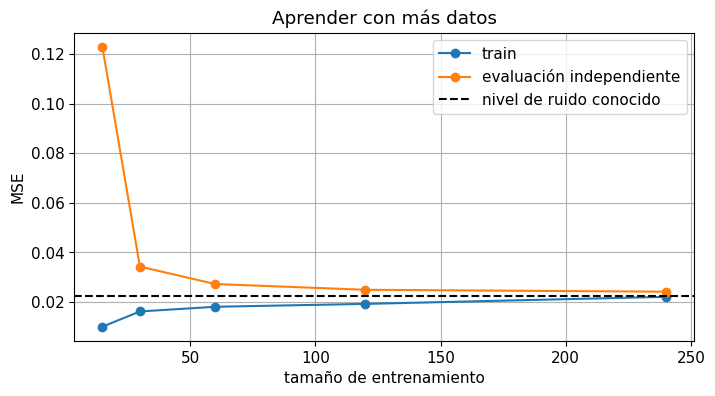

In [5]:
test_rng=np.random.default_rng(600)
Xt=test_rng.uniform(-1,1,(800,1));yt=ftrue(Xt[:,0])+test_rng.normal(0,sigma,len(Xt))
sizes=[15,30,60,120,240];train_curve=[];test_curve=[]
for n in sizes:
    tr=[];te=[]
    for repeat in range(5):
        local=np.random.default_rng(700+repeat+n)
        X=local.uniform(-1,1,(n,1));y=ftrue(X[:,0])+local.normal(0,sigma,n)
        model=make_pipeline(PolynomialFeatures(9,include_bias=False),StandardScaler(),Ridge(alpha=0.01))
        model.fit(X,y);tr.append(mean_squared_error(y,model.predict(X)));te.append(mean_squared_error(yt,model.predict(Xt)))
    train_curve.append(np.mean(tr));test_curve.append(np.mean(te))
plt.plot(sizes,train_curve,'o-',label='train');plt.plot(sizes,test_curve,'o-',label='evaluación independiente')
plt.axhline(sigma**2,c='k',ls='--',label='nivel de ruido conocido')
plt.xlabel('tamaño de entrenamiento');plt.ylabel('MSE');plt.title('Aprender con más datos');plt.legend();plt.show()

## 9. Regularización y selección adaptativa

Regularizar restringe soluciones preferidas, explícitamente con una norma o implícitamente mediante representación y entrenamiento. No siempre equivale a disminuir una dimensión VC simple, pero puede reducir sensibilidad al ruido. El valor de $\lambda$ debe seleccionarse sin mirar el test.

Seleccionar muchas variantes con un mismo conjunto de validación puede sobreajustar la validación. Un test final, validación anidada o repetir todo el procedimiento de selección ayudan a evaluar ese efecto. Reportar el mejor de muchos resultados sin describir la búsqueda oculta variabilidad.

## 10. Concentración empírica para un predictor fijo

Simulamos pérdidas binarias i.i.d. con riesgo real 0.2. El intervalo calculado con Hoeffding es una garantía conservadora para este predictor fijo y este modelo de muestreo. No es el mismo intervalo que necesitaríamos para un predictor elegido entre muchas opciones mirando estas mismas pérdidas.

In [6]:
n=200;p_error=0.2;repeats=1000
empirical=rng.binomial(n,p_error,repeats)/n
radius=np.sqrt(np.log(2/0.05)/(2*n))
coverage=np.mean(np.abs(empirical-p_error)<=radius)
print('Radio Hoeffding:',radius,'Cobertura empírica de 1000 repeticiones:',coverage)
print('Desviación típica empírica / teórica:',empirical.std(),np.sqrt(p_error*(1-p_error)/n))
assert 0<=coverage<=1

Radio Hoeffding: 0.09603227913199208 Cobertura empírica de 1000 repeticiones: 1.0
Desviación típica empírica / teórica: 0.027891810626060116 0.028284271247461905


## 11. Cambio de distribución e hipótesis físicas

Las garantías de una distribución no se trasladan automáticamente a otra. Aprender en tiempos tempranos y predecir tiempos largos, o entrenar a baja viscosidad y usar alta viscosidad, cambia la pregunta. Incorporar una ecuación puede restringir soluciones plausibles, pero no elimina error de modelo, datos ni solver.

La teoría ayuda a formular preguntas verificables: qué distribución representa el test, cuál es la unidad independiente, cuánta búsqueda hubo y qué estructura limita la clase. En aprendizaje científico conviene reportar estas decisiones junto a métricas.

In [7]:
print('Hipótesis comprobables del experimento:')
print('- función sintética fija; muestras de entrada independientes')
print('- ruido gaussiano de desviación',sigma)
print('- selección y evaluación deben usar conjuntos separados')
print('- la cota Hoeffding se mostró para pérdidas binarias acotadas, no para el MSE anterior')

Hipótesis comprobables del experimento:
- función sintética fija; muestras de entrada independientes
- ruido gaussiano de desviación 0.15
- selección y evaluación deben usar conjuntos separados
- la cota Hoeffding se mostró para pérdidas binarias acotadas, no para el MSE anterior


## Síntesis y conexión con Scientific Machine Learning

El riesgo empírico es observable; el riesgo esperado requiere supuestos sobre datos futuros. La capacidad controla posibilidades de ajuste y selección. Sesgo, varianza, ruido y optimización son fuentes diferentes. En SciML la estructura física puede mejorar información efectiva, mientras correlación temporal y cambios de régimen exigen evaluación cuidadosa.

| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../11_MACHINE_LEARNING/11_3_Unsupervised_Learning.ipynb) | [⏩](../12_DEEP_LEARNING/12_1_Neural_Networks.ipynb) |